# Model Development

This notebook uses the saved feature-engineering output to train and compare models for both vaccination targets.

**Input:** `storage/cleaned_and_engineered.csv`  
**Outputs:** trained pipelines in `storage/models/` and performance tables in `storage/results/`

The modelling workflow is:

1. Load and validate the engineered dataset.
2. Separate predictors and targets.
3. Split training and validation data.
4. Build the preprocessing pipeline.
5. Define baseline models.
6. Apply cross-validation.
7. Tune hyperparameters.
8. Evaluate tuned models.
9. Interpret important predictors.
10. Save the models and result tables.

## Import packages and create output folders

In [41]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from joblib import dump

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    RocCurveDisplay
)
from sklearn.model_selection import (
    RandomizedSearchCV,
    cross_validate,
    train_test_split
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

RANDOM_STATE = 42

STORAGE_DIR = Path("../storage/feature_engineered")
MODEL_DIR = Path("../storage/models")
RESULTS_DIR = Path("../storage/results")

MODEL_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid")

## Load the engineered dataset

In [42]:
engineered_data_path = (
    STORAGE_DIR / "cleaned_and_engineered.csv"
)

model_data_df = pd.read_csv(
    engineered_data_path
)

print("Loaded:", engineered_data_path)
print("Engineered data shape:", model_data_df.shape)
display(model_data_df.head())

Loaded: ../storage/feature_engineered/cleaned_and_engineered.csv
Engineered data shape: (26707, 38)


,respondent_id,h1n1_concern,h1n1_knowledge,behavioral_antiviral_meds,behavioral_avoidance,behavioral_face_mask,behavioral_wash_hands,behavioral_large_gatherings,behavioral_outside_home,behavioral_touch_face,doctor_recc_h1n1,doctor_recc_seasonal,chronic_med_condition,child_under_6_months,health_worker,health_insurance,opinion_h1n1_vacc_effective,opinion_h1n1_risk,opinion_h1n1_sick_from_vacc,opinion_seas_vacc_effective,opinion_seas_risk,opinion_seas_sick_from_vacc,age_group,education,race,sex,income_poverty,marital_status,rent_or_own,employment_status,hhs_geo_region,census_msa,household_adults,household_children,employment_industry,employment_occupation,h1n1_vaccine,seasonal_vaccine
0,0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,3.0,1.0,2.0,2.0,1.0,2.0,55 - 64 Years,< 12 Years,White,Female,Below Poverty,Not Married,Own,Not in Labor Force,oxchjgsf,Non-MSA,0.0,0.0,Unknown,Unknown,0,0
1,1,3.0,2.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,5.0,4.0,4.0,4.0,2.0,4.0,35 - 44 Years,12 Years,White,Male,Below Poverty,Not Married,Rent,Employed,bhuqouqj,"MSA, Not Principle City",0.0,0.0,pxcmvdjn,xgwztkwe,0,1
2,2,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,1.0,0.0,0.0,NaN,3.0,1.0,1.0,4.0,1.0,2.0,18 - 34 Years,College Graduate,White,Male,"<= $75,000, Above Poverty",Not Married,Own,Employed,qufhixun,"MSA, Not Principle City",2.0,0.0,rucpziij,xtkaffoo,0,0
3,3,1.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,NaN,3.0,3.0,5.0,5.0,4.0,1.0,65+ Years,12 Years,White,Female,Below Poverty,Not Married,Rent,Not in Labor Force,lrircsnp,"MSA, Principle City",0.0,0.0,Unknown,Unknown,0,1
4,4,2.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,NaN,3.0,3.0,2.0,3.0,1.0,4.0,45 - 54 Years,Some College,White,Female,"<= $75,000, Above Poverty",Married,Own,Employed,qufhixun,"MSA, Not Principle City",1.0,0.0,wxleyezf,emcorrxb,0,0


## Validating the laded dataset

In [43]:
required_columns = [
    "respondent_id",
    "h1n1_vaccine",
    "seasonal_vaccine"
]

assert set(required_columns).issubset(model_data_df.columns)
assert model_data_df["respondent_id"].is_unique
assert model_data_df[
    ["h1n1_vaccine", "seasonal_vaccine"]
].notna().all().all()

print("Modelling input validation passed.")

Modelling input validation passed.


## Separate predictors and target variables

- `X` contains the original and engineered predictors. The respondent ID and the two outcomes are excluded.

In [44]:
#Predictors
X = model_data_df.drop(
    columns=[
        "respondent_id",
        "h1n1_vaccine",
        "seasonal_vaccine"
    ]
)

#targets
y_h1n1 = model_data_df["h1n1_vaccine"].astype(int)
y_seasonal = model_data_df["seasonal_vaccine"].astype(int)

print("Predictor data:", X.shape)
print("H1N1 target:", y_h1n1.shape)
print("Seasonal target:", y_seasonal.shape)


Predictor data: (26707, 35)
H1N1 target: (26707,)
Seasonal target: (26707,)


## Split the training and validation data

- 80% of respondents are used for training.
- 20% are kept untouched for final validation.

In [45]:
combined_target = (
    y_h1n1.astype(str)
    + "_"
    + y_seasonal.astype(str)
)

(
    X_train,
    X_valid,
    y_h1n1_train,
    y_h1n1_valid,
    y_seasonal_train,
    y_seasonal_valid
) = train_test_split(
    X,
    y_h1n1,
    y_seasonal,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=combined_target
)

print("Training predictors:", X_train.shape)
print("Validation predictors:", X_valid.shape)
print("H1N1 training target:", y_h1n1_train.shape)
print("Seasonal training target:", y_seasonal_train.shape)

Training predictors: (21365, 35)
Validation predictors: (5342, 35)
H1N1 training target: (21365,)
Seasonal training target: (21365,)


## Build the preprocessing pipeline

Each predictor type needs different preparation:

- numeric: median imputation and standardization;
- ordinal: most-common imputation and order-preserving encoding;
- nominal: `Unknown` imputation and one-hot encoding.

The preprocessing rules are fitted only on training data when a model pipeline is trained.

In [46]:
# Ordered categorical predictors.
ordinal_columns = [
    "age_group",
    "education",
    "income_poverty"
]

# Unordered categorical predictors.
nominal_columns = [
    "race",
    "sex",
    "marital_status",
    "rent_or_own",
    "employment_status",
    "census_msa",
    "hhs_geo_region",
    "employment_industry",
    "employment_occupation"
]

# Every remaining predictor is numeric.
numeric_columns = [
    column
    for column in X.columns
    if column not in ordinal_columns + nominal_columns
]

print("Numeric columns:", len(numeric_columns))
print("Ordinal columns:", len(ordinal_columns))
print("Nominal columns:", len(nominal_columns))
print("Total grouped columns:", len(numeric_columns + ordinal_columns + nominal_columns))
print("Total X columns:", X.shape[1])

Numeric columns: 23
Ordinal columns: 3
Nominal columns: 9
Total grouped columns: 35
Total X columns: 35


In [47]:

# Correct order for the three ordinal predictors.
age_order = [
    "18 - 34 Years",
    "35 - 44 Years",
    "45 - 54 Years",
    "55 - 64 Years",
    "65+ Years"
]

education_order = [
    "< 12 Years",
    "12 Years",
    "Some College",
    "College Graduate"
]

income_order = [
    "Below Poverty",
    "<= $75,000, Above Poverty",
    "> $75,000"
]

# Numeric rules: fill missing values using the training median, then scale.
numeric_preprocessor = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)

# Ordinal rules: fill missing categories, then preserve their natural order.
ordinal_preprocessor = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "encoder",
            OrdinalEncoder(
                categories=[
                    age_order,
                    education_order,
                    income_order
                ],
                handle_unknown="use_encoded_value",
                unknown_value=-1
            )
        )
    ]
)

# Nominal rules: create an Unknown category, then one-hot encode.
# Dense output works with all three selected model families.
nominal_preprocessor = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="constant",
                fill_value="Unknown"
            )
        ),
        (
            "encoder",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            )
        )
    ]
)



# Send each group through its own transformation rules.
preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            numeric_preprocessor,
            numeric_columns
        ),
        (
            "ordinal",
            ordinal_preprocessor,
            ordinal_columns
        ),
        (
            "nominal",
            nominal_preprocessor,
            nominal_columns
        )
    ]
)

print("Preprocessor created successfully.")

Preprocessor created successfully.


## Define the baseline classification models

Three model families are compared:

- Logistic Regression: interpretable linear baseline;
- Random Forest: captures non-linear patterns and interactions;
- Gradient Boosting: builds a sequence of trees that correct earlier errors.

Each model is attached to its own copy of the preprocessor.

In [48]:

# 1. CREATE THE THREE BASELINE MODELS


logistic_regression_model = LogisticRegression(
    max_iter=2000,
    random_state=42
)

random_forest_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

gradient_boosting_model = GradientBoostingClassifier(
    random_state=42
)


# STORE THE MODELS TOGETHER


baseline_models = {
    "Logistic Regression": logistic_regression_model,
    "Random Forest": random_forest_model,
    "Gradient Boosting": gradient_boosting_model
}



# 3. CREATE A FUNCTION THAT CONNECTS A MODEL TO PREPROCESSING


def make_model_pipeline(model):

    model_pipeline = Pipeline(
        steps=[
            (
                "preprocessor",
                clone(preprocessor)
            ),
            (
                "model",
                clone(model)
            )
        ]
    )

    return model_pipeline
 

## Cross-validation on the training data

Cross-validation divides the training portion into several temporary folds. Each model trains and validates repeatedly, producing a more stable performance estimate than a single split.

The untouched 20% validation set is not used here.

In [49]:
scoring_metrics = {
    "roc_auc": "roc_auc",
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1"
}

training_targets = {
    "H1N1": y_h1n1_train,
    "Seasonal": y_seasonal_train
}

cv_rows = []

for target_name, y_train in training_targets.items():
    for model_name, model in baseline_models.items():
        model_pipeline = make_model_pipeline(model)

        cv_scores = cross_validate(
            model_pipeline,
            X_train,
            y_train,
            cv=5,
            scoring=scoring_metrics,
            n_jobs=-1
        )

        cv_rows.append(
            {
                "Target": target_name,
                "Model": model_name,
                "CV ROC-AUC": cv_scores["test_roc_auc"].mean(),
                "CV Accuracy": cv_scores["test_accuracy"].mean(),
                "CV Precision": cv_scores["test_precision"].mean(),
                "CV Recall": cv_scores["test_recall"].mean(),
                "CV F1": cv_scores["test_f1"].mean()
            }
        )

        print(f"Completed: {target_name} - {model_name}")

cv_results_df = (
    pd.DataFrame(cv_rows)
    .sort_values(["Target", "CV ROC-AUC"], ascending=[True, False])
    .reset_index(drop=True)
)

display(cv_results_df.round(3))

Completed: H1N1 - Logistic Regression
Completed: H1N1 - Random Forest
Completed: H1N1 - Gradient Boosting
Completed: Seasonal - Logistic Regression
Completed: Seasonal - Random Forest
Completed: Seasonal - Gradient Boosting


,Target,Model,CV ROC-AUC,CV Accuracy,CV Precision,CV Recall,CV F1
0,H1N1,Gradient Boosting,0.837,0.839,0.688,0.439,0.536
1,H1N1,Logistic Regression,0.833,0.836,0.681,0.427,0.524
2,H1N1,Random Forest,0.826,0.835,0.712,0.376,0.492
3,Seasonal,Gradient Boosting,0.859,0.787,0.781,0.752,0.766
4,Seasonal,Random Forest,0.852,0.780,0.774,0.745,0.759
5,Seasonal,Logistic Regression,0.851,0.778,0.773,0.739,0.756


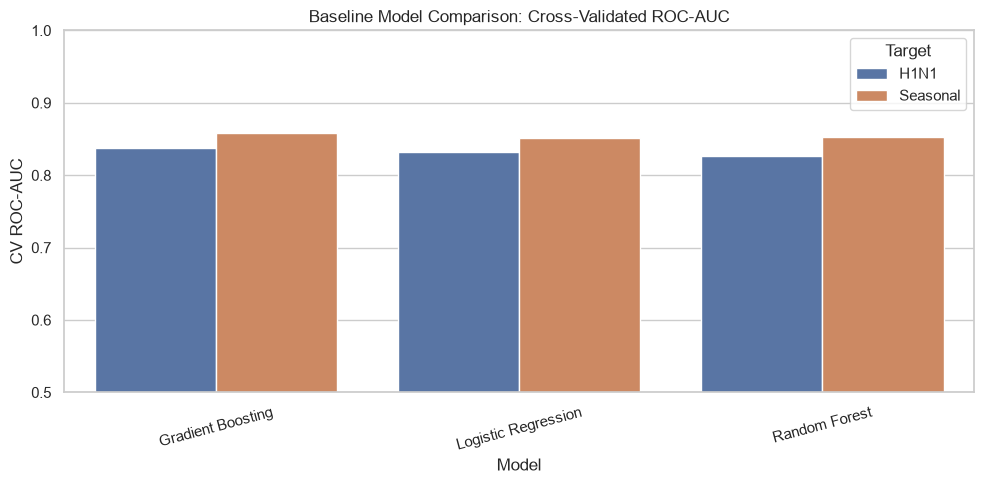

In [50]:
# Compare baseline ROC-AUC scores visually.
plt.figure(figsize=(10, 5))

sns.barplot(
    data=cv_results_df,
    x="Model",
    y="CV ROC-AUC",
    hue="Target"
)

plt.title("Baseline Model Comparison: Cross-Validated ROC-AUC")
plt.ylim(0.5, 1.0)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

## Hyperparameter tuning


In [51]:
parameter_distributions = {
    "Logistic Regression": {
        "model__C": [0.01, 0.1, 1, 10, 100],
        "model__class_weight": [None, "balanced"]
    },
    "Random Forest": {
        "model__n_estimators": [150, 250, 400],
        "model__max_depth": [None, 8, 15, 25],
        "model__min_samples_leaf": [1, 2, 5, 10],
        "model__max_features": ["sqrt", "log2"],
        "model__class_weight": [None, "balanced"]
    },
    "Gradient Boosting": {
        "model__n_estimators": [75, 100, 150, 200],
        "model__learning_rate": [0.03, 0.05, 0.1, 0.2],
        "model__max_depth": [1, 2, 3],
        "model__min_samples_leaf": [1, 5, 10]
    }
}

N_TUNING_ITERATIONS = 8

best_models = {}
tuning_rows = []

for target_name, y_train in training_targets.items():
    best_models[target_name] = {}

    for model_name, model in baseline_models.items():
        search = RandomizedSearchCV(
            estimator=make_model_pipeline(model),
            param_distributions=parameter_distributions[model_name],
            n_iter=N_TUNING_ITERATIONS,
            scoring="roc_auc",
            cv=3,
            random_state=RANDOM_STATE,
            n_jobs=-1,
            refit=True
        )

        search.fit(X_train, y_train)

        best_models[target_name][model_name] = search.best_estimator_

        tuning_rows.append(
            {
                "Target": target_name,
                "Model": model_name,
                "Best tuning ROC-AUC": search.best_score_,
                "Best parameters": search.best_params_
            }
        )

        print(f"Tuned: {target_name} - {model_name}")

tuning_results_df = (
    pd.DataFrame(tuning_rows)
    .sort_values(
        ["Target", "Best tuning ROC-AUC"],
        ascending=[True, False]
    )
    .reset_index(drop=True)
)

display(tuning_results_df)

Tuned: H1N1 - Logistic Regression
Tuned: H1N1 - Random Forest
Tuned: H1N1 - Gradient Boosting
Tuned: Seasonal - Logistic Regression
Tuned: Seasonal - Random Forest
Tuned: Seasonal - Gradient Boosting


,Target,Model,Best tuning ROC-AUC,Best parameters
0,H1N1,Gradient Boosting,0.837712,"{'model__n_estimators': 100, 'model__min_sampl..."
1,H1N1,Logistic Regression,0.833012,"{'model__class_weight': 'balanced', 'model__C'..."
2,H1N1,Random Forest,0.832376,"{'model__n_estimators': 150, 'model__min_sampl..."
3,Seasonal,Gradient Boosting,0.858538,"{'model__n_estimators': 100, 'model__min_sampl..."
4,Seasonal,Random Forest,0.854232,"{'model__n_estimators': 250, 'model__min_sampl..."
5,Seasonal,Logistic Regression,0.851043,"{'model__class_weight': None, 'model__C': 0.1}"


## Evaluate tuned models on the untouched validation data

- This code uses the tuned models to predict the untouched validation respondents, compares those predictions with their real targets, and creates the final performance table.

In [52]:
validation_targets = {
    "H1N1": y_h1n1_valid,
    "Seasonal": y_seasonal_valid
}

validation_rows = []

for target_name, y_valid in validation_targets.items():
    for model_name, fitted_pipeline in best_models[target_name].items():
        predicted_class = fitted_pipeline.predict(X_valid)
        predicted_probability = fitted_pipeline.predict_proba(X_valid)[:, 1]

        validation_rows.append(
            {
                "Target": target_name,
                "Model": model_name,
                "ROC-AUC": roc_auc_score(y_valid, predicted_probability),
                "Accuracy": accuracy_score(y_valid, predicted_class),
                "Precision": precision_score(y_valid, predicted_class, zero_division=0),
                "Recall": recall_score(y_valid, predicted_class, zero_division=0),
                "F1": f1_score(y_valid, predicted_class, zero_division=0)
            }
        )

validation_results_df = (
    pd.DataFrame(validation_rows)
    .sort_values(["Target", "ROC-AUC"], ascending=[True, False])
    .reset_index(drop=True)
)

display(validation_results_df.round(3))

,Target,Model,ROC-AUC,Accuracy,Precision,Recall,F1
0,H1N1,Gradient Boosting,0.842,0.841,0.694,0.446,0.543
1,H1N1,Random Forest,0.839,0.789,0.503,0.719,0.592
2,H1N1,Logistic Regression,0.838,0.780,0.489,0.736,0.587
3,Seasonal,Gradient Boosting,0.858,0.785,0.780,0.749,0.764
4,Seasonal,Logistic Regression,0.854,0.781,0.775,0.746,0.760
5,Seasonal,Random Forest,0.853,0.775,0.769,0.739,0.754


In [53]:
# Identify the best validation model for each target using ROC-AUC.
best_model_names = (
    validation_results_df
    .loc[
        validation_results_df.groupby("Target")["ROC-AUC"].idxmax(),
        ["Target", "Model", "ROC-AUC"]
    ]
    .reset_index(drop=True)
)

display(best_model_names.round(3))

,Target,Model,ROC-AUC
0,H1N1,Gradient Boosting,0.842
1,Seasonal,Gradient Boosting,0.858


##  Confusion matrices for the best models

The confusion matrix shows true negatives, false positives, false negatives and true positives at the 0.50 threshold.

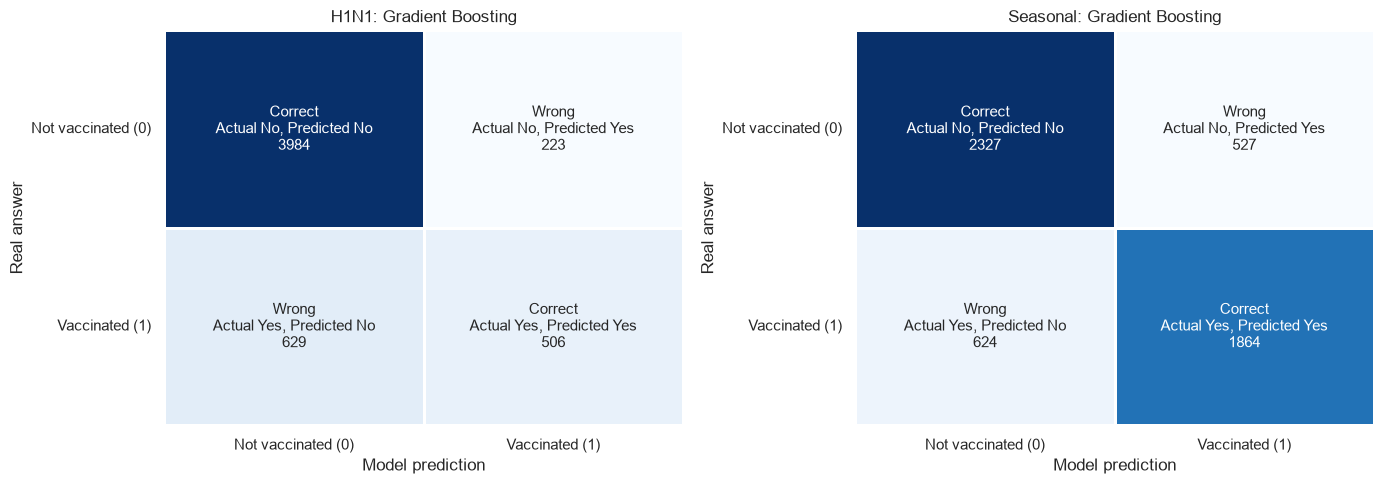

In [54]:
from sklearn.metrics import confusion_matrix
import numpy as np

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5)
)

for axis, target_name in zip(
    axes,
    ["H1N1", "Seasonal"]
):
    # Find the selected model for the current target.
    model_name = best_model_names.loc[
        best_model_names["Target"].eq(target_name),
        "Model"
    ].iloc[0]

    fitted_pipeline = best_models[
        target_name
    ][model_name]

    y_valid = validation_targets[target_name]

    # Make predictions.
    predicted_class = fitted_pipeline.predict(
        X_valid
    )

    # Create the confusion matrix.
    matrix = confusion_matrix(
        y_valid,
        predicted_class
    )

    # Add understandable labels and the number of people.
    box_labels = np.array([
    [
        f"Correct\nActual No, Predicted No\n{matrix[0, 0]}",
        f"Wrong\nActual No, Predicted Yes\n{matrix[0, 1]}"
    ],
    [
        f"Wrong\nActual Yes, Predicted No\n{matrix[1, 0]}",
        f"Correct\nActual Yes, Predicted Yes\n{matrix[1, 1]}"
    ]
])

    sns.heatmap(
        matrix,
        annot=box_labels,
        fmt="",
        cmap="Blues",
        cbar=False,
        ax=axis,
        linewidths=1,
        linecolor="white",
        annot_kws={
            "fontsize": 11
        }
    )

    axis.set_title(
        f"{target_name}: {model_name}"
    )

    axis.set_xlabel("Model prediction")
    axis.set_ylabel("Real answer")

    axis.set_xticklabels(
        [
            "Not vaccinated (0)",
            "Vaccinated (1)"
        ],
        rotation=0
    )

    axis.set_yticklabels(
        [
            "Not vaccinated (0)",
            "Vaccinated (1)"
        ],
        rotation=0
    )

plt.tight_layout()
plt.show()

##  Detailed classification reports

These reports show class-level precision, recall and F1. Class `1` represents vaccinated respondents.

In [55]:
for target_name in ["H1N1", "Seasonal"]:
    model_name = best_model_names.loc[
        best_model_names["Target"].eq(target_name),
        "Model"
    ].iloc[0]

    fitted_pipeline = best_models[target_name][model_name]
    predicted_class = fitted_pipeline.predict(X_valid)

    print(f"\n{target_name} - {model_name}")
    print(
        classification_report(
            validation_targets[target_name],
            predicted_class,
            digits=3,
            zero_division=0
        )
    )


H1N1 - Gradient Boosting
              precision    recall  f1-score   support

           0      0.864     0.947     0.903      4207
           1      0.694     0.446     0.543      1135

    accuracy                          0.841      5342
   macro avg      0.779     0.696     0.723      5342
weighted avg      0.828     0.841     0.827      5342


Seasonal - Gradient Boosting
              precision    recall  f1-score   support

           0      0.789     0.815     0.802      2854
           1      0.780     0.749     0.764      2488

    accuracy                          0.785      5342
   macro avg      0.784     0.782     0.783      5342
weighted avg      0.784     0.785     0.784      5342



## Interpret the best models

Permutation importance measures how much validation ROC-AUC decreases when one original predictor is randomly shuffled. A larger decrease suggests that the fitted pipeline relies more strongly on that predictor.

Importance is an association with prediction, not proof that the feature causes vaccination.

In [56]:
importance_tables = {}

for target_name in ["H1N1", "Seasonal"]:
    model_name = best_model_names.loc[
        best_model_names["Target"].eq(target_name),
        "Model"
    ].iloc[0]

    fitted_pipeline = best_models[target_name][model_name]

    importance_result = permutation_importance(
        fitted_pipeline,
        X_valid,
        validation_targets[target_name],
        scoring="roc_auc",
        n_repeats=5,
        random_state=RANDOM_STATE,
        n_jobs=-1
    )

    importance_df = (
        pd.DataFrame(
            {
                "Feature": X_valid.columns,
                "Importance": importance_result.importances_mean,
                "Importance SD": importance_result.importances_std
            }
        )
        .sort_values("Importance", ascending=False)
        .reset_index(drop=True)
    )

    importance_tables[target_name] = importance_df

    print(f"\nTop predictors for {target_name} ({model_name})")
    display(importance_df.head(15).round(4))


Top predictors for H1N1 (Gradient Boosting)


,Feature,Importance,Importance SD
0,doctor_recc_h1n1,0.0981,0.0028
1,opinion_h1n1_vacc_effective,0.0460,0.0018
2,opinion_h1n1_risk,0.0349,0.0030
3,health_worker,0.0073,0.0007
4,opinion_seas_risk,0.0047,0.0010
5,age_group,0.0042,0.0009
6,doctor_recc_seasonal,0.0041,0.0006
7,employment_occupation,0.0036,0.0005
8,opinion_h1n1_sick_from_vacc,0.0018,0.0002
9,sex,0.0013,0.0003



Top predictors for Seasonal (Gradient Boosting)


,Feature,Importance,Importance SD
0,opinion_seas_risk,0.0658,0.0042
1,doctor_recc_seasonal,0.0506,0.0020
2,opinion_seas_vacc_effective,0.0473,0.0022
3,age_group,0.0362,0.0011
4,opinion_seas_sick_from_vacc,0.0072,0.0012
5,health_worker,0.0045,0.0005
6,h1n1_knowledge,0.0022,0.0002
7,employment_industry,0.0016,0.0005
8,race,0.0014,0.0001
9,education,0.0013,0.0002


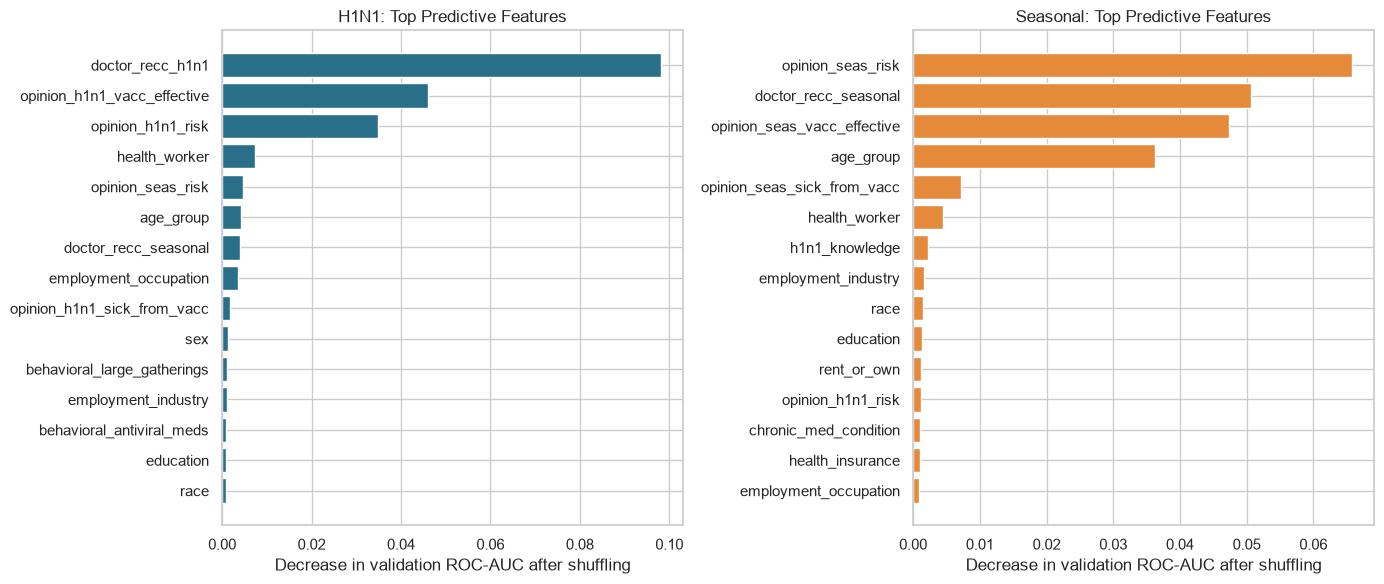

In [57]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for axis, target_name in zip(axes, ["H1N1", "Seasonal"]):
    top_features = importance_tables[target_name].head(15).sort_values("Importance")

    axis.barh(
        top_features["Feature"],
        top_features["Importance"],
        color="#2A6F8A" if target_name == "H1N1" else "#E58A3A"
    )

    axis.set_title(f"{target_name}: Top Predictive Features")
    axis.set_xlabel("Decrease in validation ROC-AUC after shuffling")

plt.tight_layout()
plt.show()

## Save the Sprint 2 deliverables

The best fitted pipeline for each target includes both preprocessing and the selected classifier. Saving the complete pipeline ensures future data receives the same transformations before prediction.

In [58]:
saved_model_paths = {}

for target_name in ["H1N1", "Seasonal"]:
    model_name = best_model_names.loc[
        best_model_names["Target"].eq(target_name),
        "Model"
    ].iloc[0]

    fitted_pipeline = best_models[target_name][model_name]

    model_path = MODEL_DIR / f"best_{target_name.lower()}_pipeline.joblib"
    dump(fitted_pipeline, model_path)
    saved_model_paths[target_name] = model_path

# Save performance tables and feature-importance tables.
cv_results_df.to_csv(
    RESULTS_DIR / "baseline_cross_validation_results.csv",
    index=False
)

tuning_results_df.to_csv(
    RESULTS_DIR / "hyperparameter_tuning_results.csv",
    index=False
)

validation_results_df.to_csv(
    RESULTS_DIR / "validation_model_comparison.csv",
    index=False
)

importance_tables["H1N1"].to_csv(
    RESULTS_DIR / "h1n1_feature_importance.csv",
    index=False
)

importance_tables["Seasonal"].to_csv(
    RESULTS_DIR / "seasonal_feature_importance.csv",
    index=False
)

print("Saved model pipelines:")
for target_name, path in saved_model_paths.items():
    print(f"- {target_name}: {path}")

print("\nSaved result tables in:", RESULTS_DIR)

Saved model pipelines:
- H1N1: ../storage/models/best_h1n1_pipeline.joblib
- Seasonal: ../storage/models/best_seasonal_pipeline.joblib

Saved result tables in: ../storage/results
